# Retinal Recognition – Feature Extraction
Skeletonises vessel maps and finds bifurcation and crossover points.
Until Person A's segmentation is ready, it is tested on the hand-marked vessel maps from DRIVE (Staal et al., 2004), 40 fundus images at 565×584.

In [6]:
import cv2
import cv2; print(cv2.__version__, hasattr(cv2, "ximgproc"))
import numpy as np
import matplotlib.pyplot as plt
from skeleton import skeletonise, prune_spurs
from bifurcations import find_points, draw_points, match_point_sets
from drive_loader import load_drive

5.0.0 True


Imports OpenCV, NumPy and Matplotlib, plus the skeleton, junction and DRIVE loading code from this folder. `cv2.ximgproc` needs `opencv-contrib-python`.

### 1. Check on Shapes with Known Answers

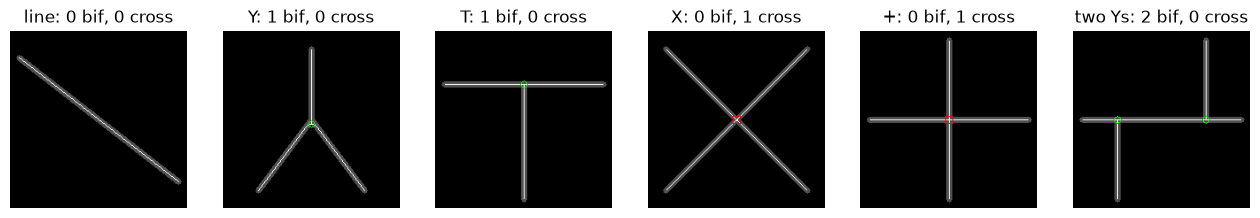

All shape checks pass


In [7]:
def shape(lines, width=5):
    m = np.zeros((200, 200), np.uint8)
    for a, b in lines:
        cv2.line(m, a, b, 255, width)
    return m

tests = {  # name: (lines, expected bifurcations, expected crossovers)
    "line": ([((10, 30), (190, 170))], 0, 0),
    "Y":    ([((100, 20), (100, 100)), ((100, 100), (40, 180)), ((100, 100), (160, 180))], 1, 0),
    "T":    ([((10, 60), (190, 60)), ((100, 60), (100, 190))], 1, 0),
    "X":    ([((20, 20), (180, 180)), ((20, 180), (180, 20))], 0, 1),
    "+":    ([((100, 10), (100, 190)), ((10, 100), (190, 100))], 0, 1),
    "two Ys": ([((10, 100), (190, 100)), ((50, 100), (50, 190)), ((150, 100), (150, 10))], 2, 0),
}

fig, axes = plt.subplots(1, len(tests), figsize=(16, 3))
for ax, (name, (lines, nb, nc)) in zip(axes, tests.items()):
    for width in (3, 5, 9):
        r = find_points(shape(lines, width))
        got = (len(r["bifurcations"]), len(r["crossovers"]))
        assert got == (nb, nc), f"{name} width {width}: got {got}, expected {(nb, nc)}"
    ax.imshow(cv2.cvtColor(draw_points(shape(lines), r), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}: {nb} bif, {nc} cross"); ax.axis("off")
plt.show()
print("All shape checks pass")

Draws simple shapes where the answer is known and checks the detector at three vessel widths. A Y and a T must give one bifurcation, an X and a + one crossover, a straight line nothing.
Green circles are bifurcations, red squares crossovers.

### 2. Load a DRIVE Hand-Marked Map

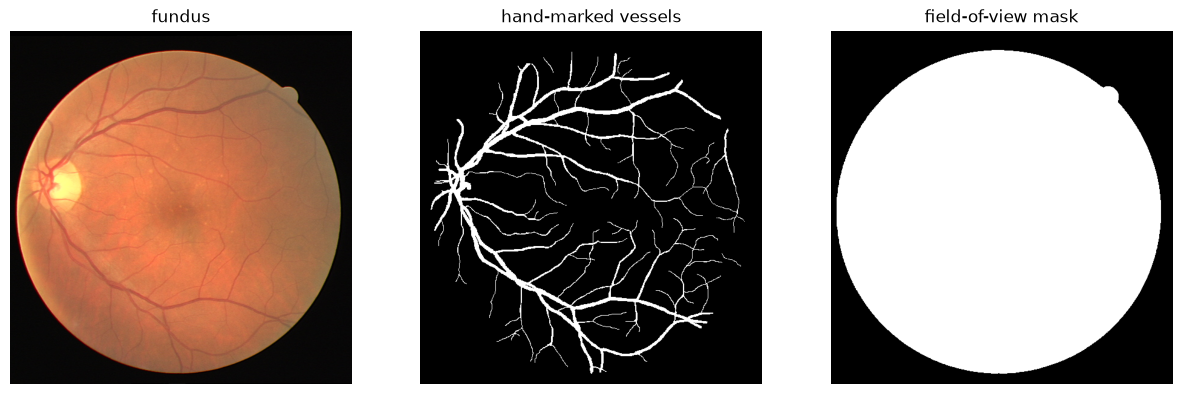

In [8]:
img, vessels, mask = load_drive(21)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axes, [img, vessels, mask], ["fundus", "hand-marked vessels", "field-of-view mask"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

DRIVE stores its vessel maps and masks as GIFs, which `cv2.imread` cannot open, so `drive_loader.py` reads them with Pillow. Images 1–20 are the test set, 21–40 training.

### 3. Skeletonisation

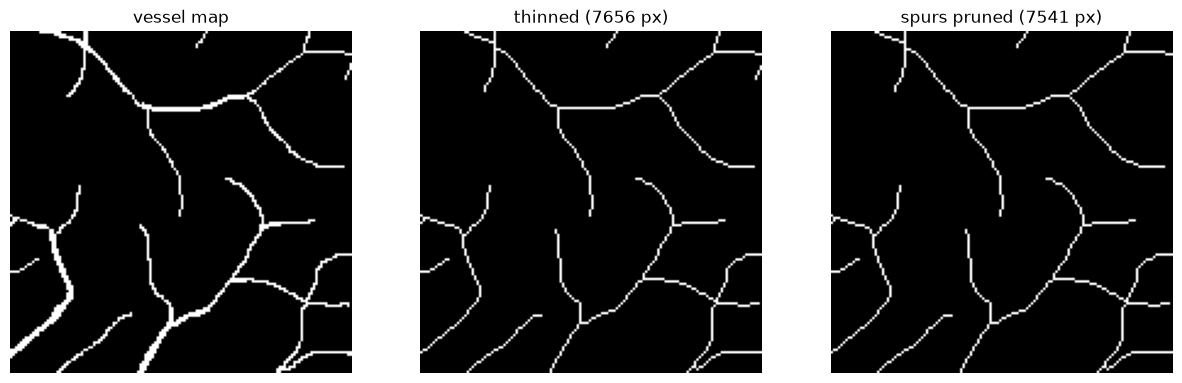

In [9]:
raw = skeletonise(vessels)
pruned = prune_spurs(raw, max_len=10)

y0, x0, s = 250, 330, 140  # zoomed crop
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(vessels[y0:y0+s, x0:x0+s], cmap="gray"); axes[0].set_title("vessel map")
axes[1].imshow(raw[y0:y0+s, x0:x0+s], cmap="gray");     axes[1].set_title(f"thinned ({raw.sum()} px)")
axes[2].imshow(pruned[y0:y0+s, x0:x0+s], cmap="gray");  axes[2].set_title(f"spurs pruned ({pruned.sum()} px)")
for a in axes: a.axis("off")
plt.show()

`cv2.ximgproc.thinning` (Zhang-Suen) reduces every vessel to a 1-pixel centre line. Two clean-ups follow:
- **Staircase removal**: Zhang-Suen leaves L-shaped steps on diagonal vessels. The corner pixel of each step is deleted so the line is strictly 8-connected.
- **Spur pruning**: small bumps on a vessel edge thin into short side branches, each a fake bifurcation. Any branch from an end point that reaches a junction within 10 px is removed.

### 4. Bifurcations and Crossovers

65 bifurcations, 39 crossovers


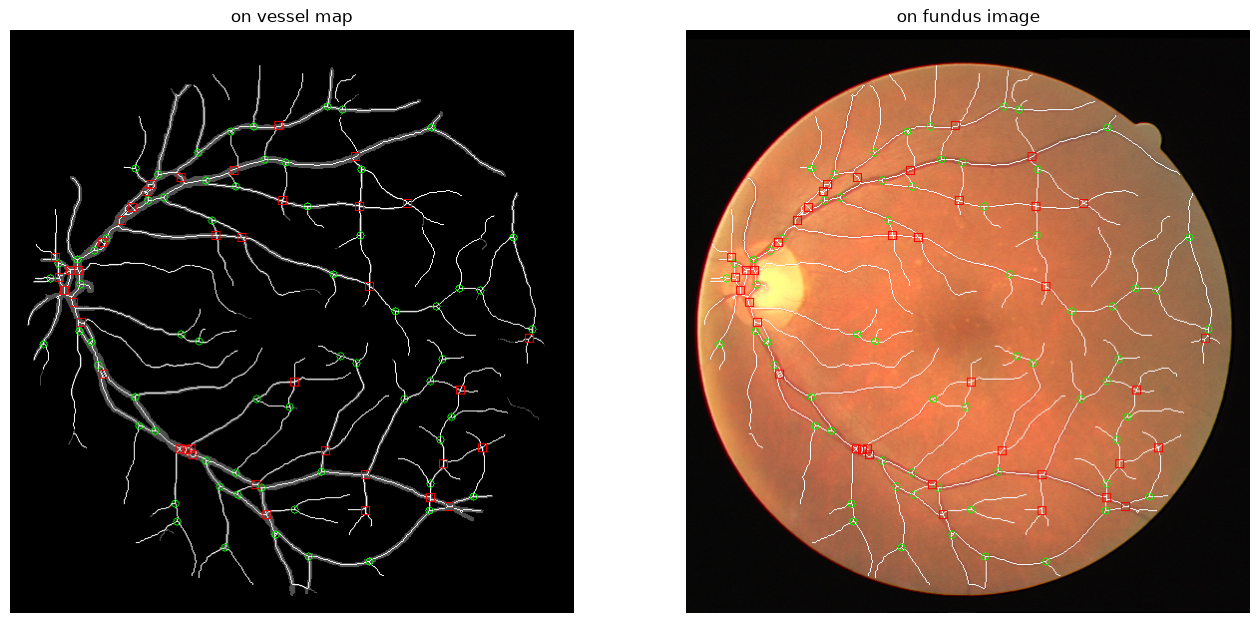

In [10]:
r = find_points(vessels, mask)
print(len(r["bifurcations"]), "bifurcations,", len(r["crossovers"]), "crossovers")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(cv2.cvtColor(draw_points(vessels, r), cv2.COLOR_BGR2RGB)); axes[0].set_title("on vessel map")
bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # draw_points uses OpenCV's BGR order
axes[1].imshow(cv2.cvtColor(draw_points(bgr, r), cv2.COLOR_BGR2RGB)); axes[1].set_title("on fundus image")
for a in axes: a.axis("off")
plt.show()

Junction candidates are skeleton pixels with 3 or more neighbours. Touching candidates are grouped into one junction, and the branches leaving it are counted by looking at the skeleton in a ring 2 px around the group: 3 branches = bifurcation, 4 = crossover.

Two vessels crossing at an angle usually thin into two bifurcations joined by a short segment, so pairs of bifurcations under 15 px apart are merged into one crossover. Points within 10 px of the mask edge are dropped, because vessels cut off by the field of view create fake junctions there.

### 5. All 40 DRIVE Maps

Bifurcations per image: mean 63.8, range 20-94
Crossovers per image:   mean 53.4, range 25-90


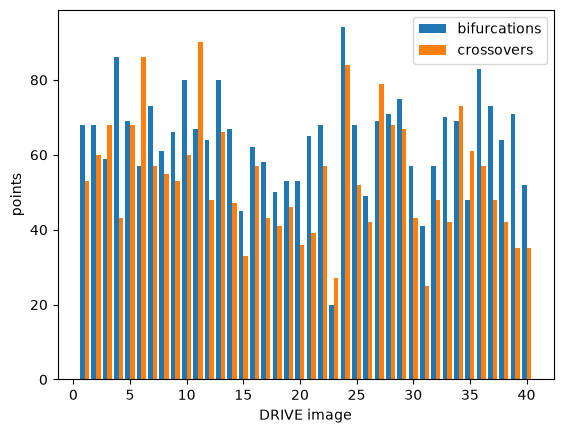

In [11]:
counts = []
for i in range(1, 41):
    _, v, m = load_drive(i)
    r = find_points(v, m)
    counts.append((len(r["bifurcations"]), len(r["crossovers"])))
counts = np.array(counts)
print(f"Bifurcations per image: mean {counts[:, 0].mean():.1f}, range {counts[:, 0].min()}-{counts[:, 0].max()}")
print(f"Crossovers per image:   mean {counts[:, 1].mean():.1f}, range {counts[:, 1].min()}-{counts[:, 1].max()}")

plt.bar(np.arange(1, 41) - 0.2, counts[:, 0], 0.4, label="bifurcations")
plt.bar(np.arange(1, 41) + 0.2, counts[:, 1], 0.4, label="crossovers")
plt.xlabel("DRIVE image"); plt.ylabel("points"); plt.legend(); plt.show()

Runs the detector on every hand-marked map to check it gives a sensible, consistent number of points per image.

### 6. Agreement Between Two Human Markers

In [12]:
P, R = [], []
for i in range(1, 21):
    _, v1, m = load_drive(i, observer=1)
    _, v2, _ = load_drive(i, observer=2)
    a, b = find_points(v1, m), find_points(v2, m)
    pa = np.vstack([a["bifurcations"], a["crossovers"]])
    pb = np.vstack([b["bifurcations"], b["crossovers"]])
    _, p, rc = match_point_sets(pa, pb, tol=6)
    P.append(p); R.append(rc)
print(f"Points from observer 1's map found in observer 2's (within 6 px): {np.mean(R):.0%}")
print(f"Points from observer 2's map found in observer 1's (within 6 px): {np.mean(P):.0%}")

Points from observer 1's map found in observer 2's (within 6 px): 76%
Points from observer 2's map found in observer 1's (within 6 px): 74%


The 20 DRIVE test images were hand-marked by two different people. Running the detector on both maps of the same eye and pairing points within 6 px shows how repeatable the points are when the vessel map changes slightly. This is the situation matching will face, since Person A's segmentation of two images of the same eye will never be identical.